# Lesson 1 — South African Underwater Acoustic Data

## Zindi French Embassy Underwater Vessel Noise Challenge

### Objectives

1. Understand the structure of the acoustic dataset.
2. Investigate the ten monitoring stations.
3. Examine recording equipment and sampling coverage.
4. Identify missing data and unusual measurements.
5. Understand acoustic energy expressed in decibels.
6. Establish a foundation for synthetic vessel-noise modelling.
7. Review the validated background and VTUAD source splits.
8. Check acoustic feature extraction and the first synthetic-mixture experiment.

### Competition boundary

This notebook begins with the released South African acoustic archive and then reviews our completed VTUAD and synthetic-mixture work. The new review sections use locally generated project files, not the hidden challenge-test measurements.

Test.csv is inference-only and will not be used for model training,
calibration, pseudo-labelling or synthetic training-data generation.


In [57]:
from pathlib import Path
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt

# Works whether Jupyter starts in the repository root or notebooks/.
_here = Path.cwd().resolve()
_candidates = [_here, *_here.parents]
PROJECT_ROOT = next(
    (p for p in _candidates if (p / "data" / "zindi" / "extracted").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find the project root. Open this notebook from the challenge repository."
    )
DATA_DIR = PROJECT_ROOT / "data" / "zindi" / "extracted"
REPORT_DIR = PROJECT_ROOT / "reports" / "eda"

REPORT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Data directory exists:", DATA_DIR.exists())

parquet_files = sorted(DATA_DIR.rglob("*.parquet"))

print("Parquet files discovered:", len(parquet_files))

for path in parquet_files:
    print(path.relative_to(DATA_DIR))


Project root: /Users/qwaku/Codes/QBE/Zindi/french-embassy-underwater-vessel-noise-challenge
Data directory exists: True
Parquet files discovered: 10
acoustics/01_Richards_Bay.parquet
acoustics/02_Durban.parquet
acoustics/03_Cape_Recife.parquet
acoustics/04_Bird_Island.parquet
acoustics/05_St_Croix_Island.parquet
acoustics/06_Riy_Banks.parquet
acoustics/07_St_Francis.parquet
acoustics/09_Fish_Hoek.parquet
acoustics/10_Sea_Point.parquet
acoustics/13_Saldhana_Bay.parquet


In [58]:
# Inspect schema without loading the entire dataset.
first_file = parquet_files[0]

pf = pq.ParquetFile(first_file)

print("File:", first_file.name)
print("Rows:", pf.metadata.num_rows)
print("Columns:", pf.metadata.num_columns)

print("\nColumn names:")
for col in pf.schema_arrow.names:
    print(col)

# Read a small batch for exploration.
batch = next(pf.iter_batches(batch_size=1000))
sample = batch.to_pandas()

display(sample.head())
print("\nSample dimensions:", sample.shape)


File: 01_Richards_Bay.parquet
Rows: 1001174
Columns: 74

Column names:
site
recorder
station_token
sample_rate_hz
file_kind
src_file
file_date
t
dur
TOL_0.8
TOL_1
TOL_1.3
TOL_1.6
TOL_2
TOL_2.5
TOL_3.2
TOL_4
TOL_5
TOL_6.3
TOL_7.9
TOL_10
TOL_12.6
TOL_15.8
TOL_20
TOL_25.1
TOL_31.6
TOL_39.8
TOL_50.1
TOL_63.1
TOL_79.4
TOL_100
TOL_125.9
TOL_158.5
TOL_199.5
TOL_251.2
TOL_316.2
TOL_398.1
TOL_501.2
TOL_631
TOL_794.3
TOL_1000
TOL_1258.9
TOL_1584.9
TOL_1995.3
TOL_2511.9
TOL_3162.3
TOL_3981.1
TOL_5011.9
TOL_6309.6
TOL_7943.3
TOL_10000
TOL_12000
TOL_12589.3
TOL_15848.9
TOL_19952.6
TOL_24000
TOL_25118.9
TOL_31622.8
TOL_39810.7
TOL_48000
TOL_50118.7
TOL_63095.7
TOL_72000
TOL_79432.8
TOL_100000
TOL_125892.5
TOL_158489.3
TOL_192000
TOL_199526.2
TOL_251188.6
TOL_288000
qc_duration_ge55
qc_25band_finite
qc_25band_spread_ge6


,site,recorder,station_token,sample_rate_hz,file_kind,src_file,file_date,t,dur,TOL_0.8,...,TOL_100000,TOL_125892.5,TOL_158489.3,TOL_192000,TOL_199526.2,TOL_251188.6,TOL_288000,qc_duration_ge55,qc_25band_finite,qc_25band_spread_ge6
0,1 Richards Bay,201383949_Richards_Bay_201383949.1.24000,201383949,24000,MinRes,201383949_Richards_Bay_201383949.1.24000_20170...,20170509,2017-05-09 00:00:02,58.0,131.600006,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,True,True
1,1 Richards Bay,201383949_Richards_Bay_201383949.1.24000,201383949,24000,MinRes,201383949_Richards_Bay_201383949.1.24000_20170...,20170509,2017-05-09 00:01:00,60.0,131.199997,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,True,True
2,1 Richards Bay,201383949_Richards_Bay_201383949.1.24000,201383949,24000,MinRes,201383949_Richards_Bay_201383949.1.24000_20170...,20170509,2017-05-09 00:02:00,60.0,131.199997,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,True,True
3,1 Richards Bay,201383949_Richards_Bay_201383949.1.24000,201383949,24000,MinRes,201383949_Richards_Bay_201383949.1.24000_20170...,20170509,2017-05-09 00:03:00,60.0,131.199997,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,True,True
4,1 Richards Bay,201383949_Richards_Bay_201383949.1.24000,201383949,24000,MinRes,201383949_Richards_Bay_201383949.1.24000_20170...,20170509,2017-05-09 00:04:00,60.0,131.199997,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,True,True



Sample dimensions: (1000, 74)


In [59]:
print("Column types:")
display(sample.dtypes.to_frame("dtype"))

print("\nNumeric columns:")
numeric_columns = sample.select_dtypes(
    include="number"
).columns.tolist()

print(numeric_columns)
print("Numeric column count:", len(numeric_columns))


Column types:


,dtype
site,str
recorder,str
station_token,str
sample_rate_hz,int32
file_kind,str
...,...
TOL_251188.6,float32
TOL_288000,float32
qc_duration_ge55,bool
qc_25band_finite,bool



Numeric columns:
['sample_rate_hz', 'dur', 'TOL_0.8', 'TOL_1', 'TOL_1.3', 'TOL_1.6', 'TOL_2', 'TOL_2.5', 'TOL_3.2', 'TOL_4', 'TOL_5', 'TOL_6.3', 'TOL_7.9', 'TOL_10', 'TOL_12.6', 'TOL_15.8', 'TOL_20', 'TOL_25.1', 'TOL_31.6', 'TOL_39.8', 'TOL_50.1', 'TOL_63.1', 'TOL_79.4', 'TOL_100', 'TOL_125.9', 'TOL_158.5', 'TOL_199.5', 'TOL_251.2', 'TOL_316.2', 'TOL_398.1', 'TOL_501.2', 'TOL_631', 'TOL_794.3', 'TOL_1000', 'TOL_1258.9', 'TOL_1584.9', 'TOL_1995.3', 'TOL_2511.9', 'TOL_3162.3', 'TOL_3981.1', 'TOL_5011.9', 'TOL_6309.6', 'TOL_7943.3', 'TOL_10000', 'TOL_12000', 'TOL_12589.3', 'TOL_15848.9', 'TOL_19952.6', 'TOL_24000', 'TOL_25118.9', 'TOL_31622.8', 'TOL_39810.7', 'TOL_48000', 'TOL_50118.7', 'TOL_63095.7', 'TOL_72000', 'TOL_79432.8', 'TOL_100000', 'TOL_125892.5', 'TOL_158489.3', 'TOL_192000', 'TOL_199526.2', 'TOL_251188.6', 'TOL_288000']
Numeric column count: 64


,missing_percent
TOL_25118.9,100.0
TOL_100000,100.0
TOL_12000,100.0
TOL_31622.8,100.0
TOL_39810.7,100.0
TOL_48000,100.0
TOL_50118.7,100.0
TOL_72000,100.0
TOL_79432.8,100.0
TOL_63095.7,100.0


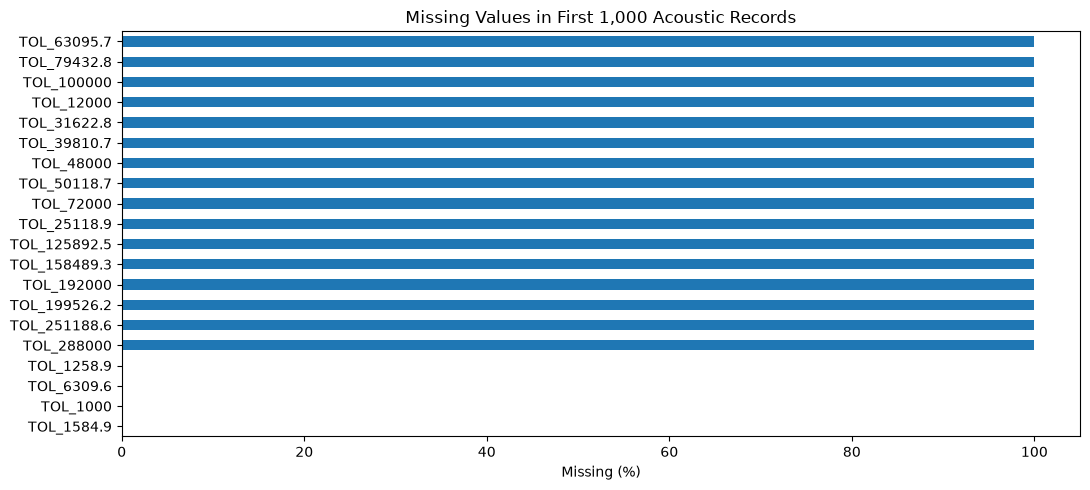

In [60]:
missing = (
    sample.isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

display(
    missing.head(25).to_frame("missing_percent")
)

fig, ax = plt.subplots(figsize=(11, 5))

missing.head(20).sort_values().plot(
    kind="barh",
    ax=ax
)

ax.set_title("Missing Values in First 1,000 Acoustic Records")
ax.set_xlabel("Missing (%)")

plt.tight_layout()
plt.show()


In [61]:
levels_db = np.array([60, 70, 80, 90], dtype=float)

relative_energy = 10 ** (levels_db / 10)

example = pd.DataFrame({
    "Level (dB)": levels_db,
    "Relative energy": relative_energy
})

example["Energy ratio to 60 dB"] = (
    example["Relative energy"] /
    example["Relative energy"].iloc[0]
)

display(example)


,Level (dB),Relative energy,Energy ratio to 60 dB
0,60.0,1.000000e+06,1.0
1,70.0,1.000000e+07,10.0
2,80.0,1.000000e+08,100.0
3,90.0,1.000000e+09,1000.0


## 2. Comparing All Ten Acoustic Monitoring Stations

,file,rows,columns,band_columns,first_timestamp,last_timestamp,pct_missing_bands,rows_duration_under55,rows_duration_not60,recorders
0,acoustics/01_Richards_Bay.parquet,1001174,74,62,2017-05-09 00:00:02,2024-05-25 23:59:00,23.578,15691,27415,3
1,acoustics/02_Durban.parquet,44640,74,62,2025-10-28 00:00:00,2025-12-06 23:59:00,30.645,0,16,1
2,acoustics/03_Cape_Recife.parquet,5928,74,62,2024-03-05 00:00:00,2024-03-23 23:12:00,25.806,0,0,1
3,acoustics/04_Bird_Island.parquet,47552,74,62,2022-03-21 05:59:58,2024-06-29 23:59:00,30.718,32,60,2
4,acoustics/05_St_Croix_Island.parquet,250717,74,62,2022-04-05 00:00:00,2025-09-20 06:00:00,31.728,130,282,3
5,acoustics/06_Riy_Banks.parquet,4121,74,62,2024-03-05 00:00:00,2024-04-05 23:12:00,25.806,0,0,1
6,acoustics/07_St_Francis.parquet,169488,74,62,2015-04-21 00:00:00,2018-02-28 14:24:00,25.806,1,2,1
7,acoustics/09_Fish_Hoek.parquet,53767,74,62,2016-09-13 00:00:02,2021-09-28 12:45:00,21.373,1014,8296,2
8,acoustics/10_Sea_Point.parquet,3660,74,62,2018-10-11 10:00:02,2018-10-13 23:59:00,17.742,0,2,1
9,acoustics/13_Saldhana_Bay.parquet,134732,74,62,2022-03-22 00:00:00,2023-05-29 04:34:00,25.806,28,161,2


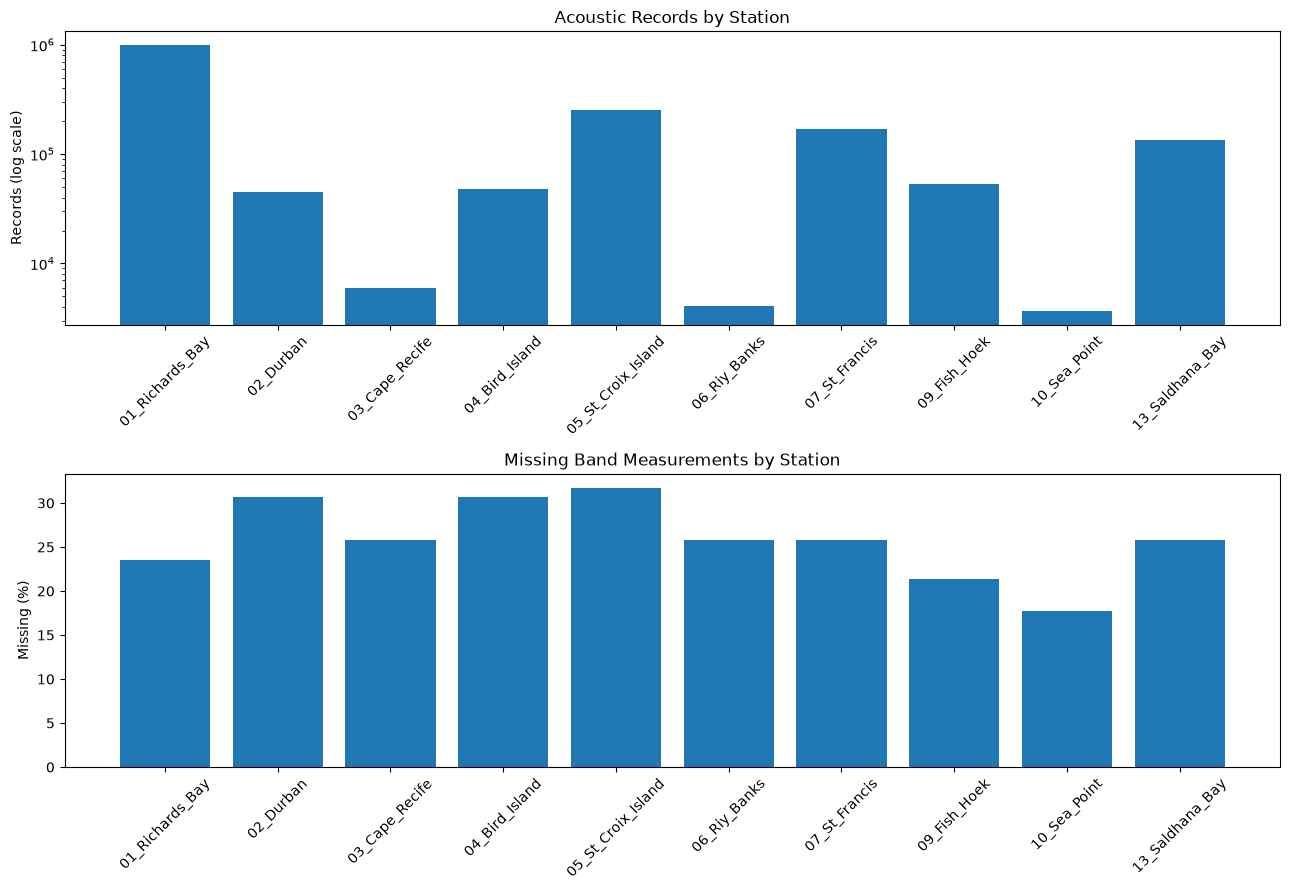

In [62]:
# Read the station-level audit we already generated.
audit_path = (
    PROJECT_ROOT
    / "reports"
    / "zindi_audit"
    / "station_acoustic_audit.csv"
)

station_audit = pd.read_csv(audit_path)

display(station_audit)

# Visualize station recording coverage.
station_audit["station"] = (
    station_audit["file"]
    .str.replace(".parquet", "", regex=False)
    .str.split("/")
    .str[-1]
)

fig, axes = plt.subplots(2, 1, figsize=(13, 9))

# Number of recordings per station.
axes[0].bar(
    station_audit["station"],
    station_audit["rows"]
)

axes[0].set_yscale("log")
axes[0].set_title("Acoustic Records by Station")
axes[0].set_ylabel("Records (log scale)")
axes[0].tick_params(axis="x", rotation=45)

# Missing acoustic band percentage.
axes[1].bar(
    station_audit["station"],
    station_audit["pct_missing_bands"]
)

axes[1].set_title("Missing Band Measurements by Station")
axes[1].set_ylabel("Missing (%)")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


In [63]:
total_records = station_audit["rows"].sum()

station_audit["share_of_records_pct"] = (
    100 * station_audit["rows"] / total_records
)

summary = station_audit[
    ["station", "rows", "share_of_records_pct", "recorders"]
].sort_values("rows", ascending=False)

display(summary)

print(f"Total records: {total_records:,}")

print(
    "Largest station share:",
    f"{summary['share_of_records_pct'].iloc[0]:.2f}%"
)

,station,rows,share_of_records_pct,recorders
0,01_Richards_Bay,1001174,58.350988,3
4,05_St_Croix_Island,250717,14.612430,3
6,07_St_Francis,169488,9.878195,1
9,13_Saldhana_Bay,134732,7.852526,2
7,09_Fish_Hoek,53767,3.133679,2
3,04_Bird_Island,47552,2.771453,2
1,02_Durban,44640,2.601734,1
2,03_Cape_Recife,5928,0.345499,1
5,06_Riy_Banks,4121,0.240182,1
8,10_Sea_Point,3660,0.213314,1


Total records: 1,715,779
Largest station share: 58.35%


## 3. Identifying the Competition's 25 Frequency Bands

In [64]:
# Read only the CSV header: no test measurements are loaded.
test_path = PROJECT_ROOT / "data" / "zindi" / "raw" / "Test.csv"

test_columns = pd.read_csv(test_path, nrows=0).columns.tolist()

print("Total test columns:", len(test_columns))

feature_columns = [
    col for col in test_columns if col != "ID"
]

print("Acoustic features:", len(feature_columns))

print("\nFirst 20 features:")
print(feature_columns[:20])

print("\nLast 20 features:")
print(feature_columns[-20:])

Total test columns: 376
Acoustic features: 375

First 20 features:
['m01_TOL_31.6', 'm01_TOL_39.8', 'm01_TOL_50.1', 'm01_TOL_63.1', 'm01_TOL_79.4', 'm01_TOL_100', 'm01_TOL_125.9', 'm01_TOL_158.5', 'm01_TOL_199.5', 'm01_TOL_251.2', 'm01_TOL_316.2', 'm01_TOL_398.1', 'm01_TOL_501.2', 'm01_TOL_631', 'm01_TOL_794.3', 'm01_TOL_1000', 'm01_TOL_1258.9', 'm01_TOL_1584.9', 'm01_TOL_1995.3', 'm01_TOL_2511.9']

Last 20 features:
['m15_TOL_100', 'm15_TOL_125.9', 'm15_TOL_158.5', 'm15_TOL_199.5', 'm15_TOL_251.2', 'm15_TOL_316.2', 'm15_TOL_398.1', 'm15_TOL_501.2', 'm15_TOL_631', 'm15_TOL_794.3', 'm15_TOL_1000', 'm15_TOL_1258.9', 'm15_TOL_1584.9', 'm15_TOL_1995.3', 'm15_TOL_2511.9', 'm15_TOL_3162.3', 'm15_TOL_3981.1', 'm15_TOL_5011.9', 'm15_TOL_6309.6', 'm15_TOL_7943.3']


In [65]:
import re

# Extract possible frequency labels from test feature names.
frequencies = set()

for col in feature_columns:
    matches = re.findall(r"TOL_([0-9]+(?:\.[0-9]+)?)", col)
    frequencies.update(matches)

frequencies = sorted(frequencies, key=float)

print("Frequency bands discovered:", len(frequencies))
print(frequencies)


Frequency bands discovered: 25
['31.6', '39.8', '50.1', '63.1', '79.4', '100', '125.9', '158.5', '199.5', '251.2', '316.2', '398.1', '501.2', '631', '794.3', '1000', '1258.9', '1584.9', '1995.3', '2511.9', '3162.3', '3981.1', '5011.9', '6309.6', '7943.3']


In [66]:
archive_band_columns = [
    col for col in sample.columns
    if col.startswith("TOL_")
]

expected_band_columns = [
    f"TOL_{freq}" for freq in frequencies
]

available = [
    col for col in expected_band_columns
    if col in archive_band_columns
]

missing = [
    col for col in expected_band_columns
    if col not in archive_band_columns
]

print("Expected competition bands:", len(expected_band_columns))
print("Available in archive:", len(available))
print("Unavailable in archive:", missing)

Expected competition bands: 25
Available in archive: 25
Unavailable in archive: []


## 4. Competition Band Coverage Across All Stations

In [67]:
# Analyze the exact 25 competition bands across all stations.
# Process one Parquet batch at a time to limit memory use.

band_columns = expected_band_columns

coverage_records = []

for file in parquet_files:
    parquet = pq.ParquetFile(file)
    total = 0
    valid_counts = np.zeros(len(band_columns), dtype=np.int64)

    for batch in parquet.iter_batches(
        batch_size=50000,
        columns=band_columns
    ):
        values = batch.to_pandas()[band_columns].to_numpy(
            dtype=np.float64
        )

        valid_counts += np.isfinite(values).sum(axis=0)
        total += values.shape[0]

    for band, valid_count in zip(
        band_columns, valid_counts
    ):
        coverage_records.append({
            "station": file.stem,
            "band": band,
            "total_rows": total,
            "valid_rows": int(valid_count),
            "coverage_pct": (
                100 * valid_count / total if total else np.nan
            )
        })

coverage_df = pd.DataFrame(coverage_records)

coverage_matrix = coverage_df.pivot(
    index="station",
    columns="band",
    values="coverage_pct"
)[band_columns]

display(coverage_matrix.round(2))

band,TOL_31.6,TOL_39.8,TOL_50.1,TOL_63.1,TOL_79.4,TOL_100,TOL_125.9,TOL_158.5,TOL_199.5,TOL_251.2,...,TOL_1000,TOL_1258.9,TOL_1584.9,TOL_1995.3,TOL_2511.9,TOL_3162.3,TOL_3981.1,TOL_5011.9,TOL_6309.6,TOL_7943.3
station,,,,,,,,,,,,,,,,,,,,,
01_Richards_Bay,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,...,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
02_Durban,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,...,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
03_Cape_Recife,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,...,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
04_Bird_Island,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,...,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
05_St_Croix_Island,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,...,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
06_Riy_Banks,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,...,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
07_St_Francis,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,...,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
09_Fish_Hoek,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,...,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
10_Sea_Point,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,...,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0


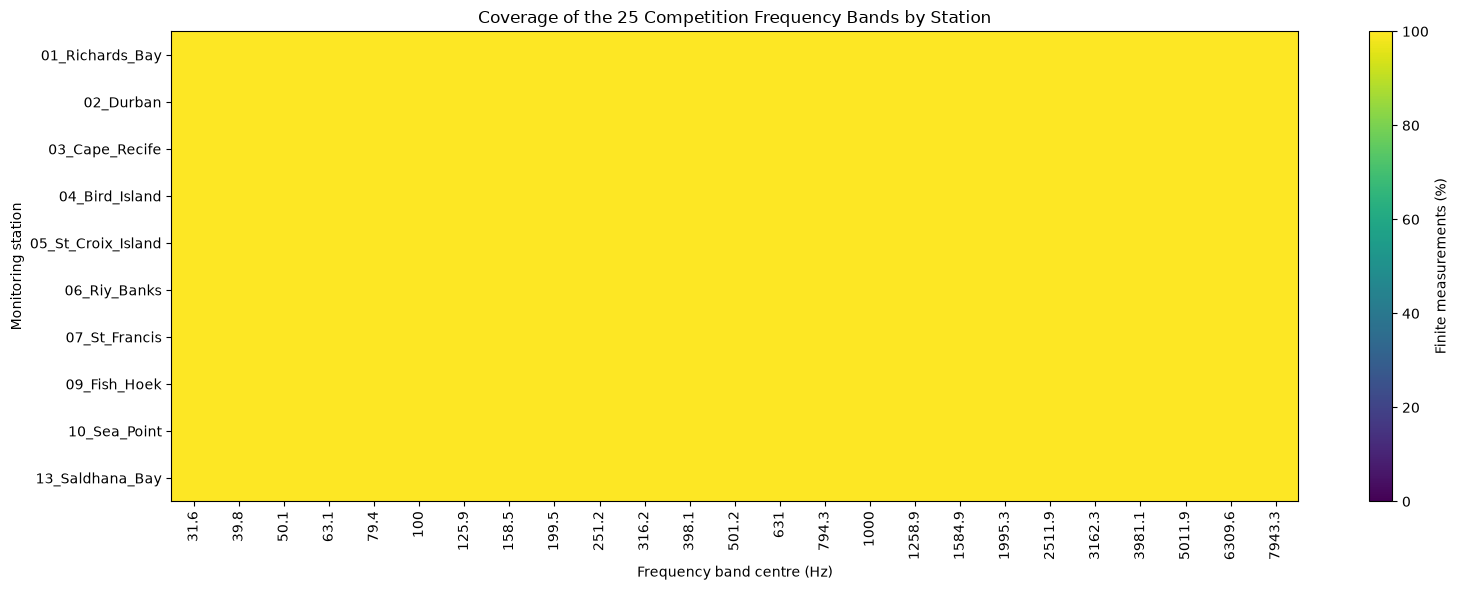

In [68]:
fig, ax = plt.subplots(figsize=(16, 6))

im = ax.imshow(
    coverage_matrix.to_numpy(),
    aspect="auto",
    vmin=0,
    vmax=100,
    cmap="viridis"
)

ax.set_xticks(range(len(band_columns)))
ax.set_xticklabels(
    [b.replace("TOL_", "") for b in band_columns],
    rotation=90
)

ax.set_yticks(range(len(coverage_matrix)))
ax.set_yticklabels(coverage_matrix.index)

ax.set_title(
    "Coverage of the 25 Competition Frequency Bands by Station"
)
ax.set_xlabel("Frequency band centre (Hz)")
ax.set_ylabel("Monitoring station")

fig.colorbar(im, ax=ax, label="Finite measurements (%)")

plt.tight_layout()
plt.show()


In [69]:
complete_records = []

for file in parquet_files:
    parquet = pq.ParquetFile(file)

    total_rows = 0
    complete_rows = 0

    for batch in parquet.iter_batches(
        batch_size=50000,
        columns=band_columns
    ):
        values = batch.to_pandas().to_numpy(
            dtype=np.float64
        )

        finite = np.isfinite(values)

        total_rows += len(values)
        complete_rows += finite.all(axis=1).sum()

    complete_records.append({
        "station": file.stem,
        "total_rows": total_rows,
        "complete_25_band_rows": int(complete_rows),
        "complete_pct": (
            100 * complete_rows / total_rows
            if total_rows else np.nan
        )
    })

complete_df = pd.DataFrame(complete_records)

display(
    complete_df.sort_values(
        "complete_pct",
        ascending=False
    )
)

print(
    "Overall complete 25-band coverage:",
    f"{100 * complete_df['complete_25_band_rows'].sum() / complete_df['total_rows'].sum():.2f}%"
)


,station,total_rows,complete_25_band_rows,complete_pct
0,01_Richards_Bay,1001174,1001174,100.0
1,02_Durban,44640,44640,100.0
2,03_Cape_Recife,5928,5928,100.0
3,04_Bird_Island,47552,47552,100.0
4,05_St_Croix_Island,250717,250717,100.0
5,06_Riy_Banks,4121,4121,100.0
6,07_St_Francis,169488,169488,100.0
7,09_Fish_Hoek,53767,53767,100.0
8,10_Sea_Point,3660,3660,100.0
9,13_Saldhana_Bay,134732,134732,100.0


Overall complete 25-band coverage: 100.00%


## 5. Temporal Continuity and 15-Minute Background Window Availability

In [70]:
# Analyze temporal continuity without loading acoustic band values.
# Only timestamps, recorder IDs and durations are read.

continuity_records = []

for file in parquet_files:
    station = file.stem

    df = pd.read_parquet(
        file,
        columns=["recorder", "t", "dur"]
    )

    df["t"] = pd.to_datetime(df["t"])

    station_valid_windows = 0
    station_continuous_runs = 0
    station_duplicates = 0
    station_short_duration = 0
    station_max_run = 0

    for recorder, group in df.groupby("recorder"):
        group = group.sort_values("t").reset_index(drop=True)

        duplicate = group["t"].duplicated(keep=False)
        station_duplicates += int(duplicate.sum())

        # Use only full or nearly full minute measurements.
        valid_duration = (
            group["dur"].ge(55)
            & group["dur"].le(65)
        )

        station_short_duration += int(
            (~valid_duration).sum()
        )

        # Allow small timestamp offsets caused by exports.
        delta_seconds = group["t"].diff().dt.total_seconds()

        continuous_edge = delta_seconds.between(
            58, 62, inclusive="both"
        )

        # Separate runs at timestamp gaps, invalid durations
        # and duplicate timestamps.
        previous_valid = valid_duration.shift(
            1, fill_value=False
        )

        run_start = ~(
            continuous_edge
            & valid_duration
            & previous_valid
            & ~duplicate
            & ~duplicate.shift(1, fill_value=False)
        )

        run_id = run_start.cumsum()

        valid_group = group.loc[
            valid_duration & ~duplicate
        ].copy()

        valid_group["run_id"] = run_id.loc[
            valid_duration & ~duplicate
        ].to_numpy()

        run_lengths = valid_group.groupby("run_id").size()

        station_continuous_runs += len(run_lengths)

        if len(run_lengths):
            station_max_run = max(
                station_max_run,
                int(run_lengths.max())
            )

            # Conservative, non-overlapping 15-minute windows.
            station_valid_windows += int(
                (run_lengths // 15).sum()
            )

    continuity_records.append({
        "station": station,
        "records": len(df),
        "duplicate_timestamp_rows": station_duplicates,
        "invalid_duration_rows": station_short_duration,
        "continuous_runs": station_continuous_runs,
        "longest_run_minutes": station_max_run,
        "nonoverlapping_15min_windows": station_valid_windows
    })

continuity_df = pd.DataFrame(continuity_records)

display(
    continuity_df.sort_values(
        "nonoverlapping_15min_windows",
        ascending=False
    )
)

print(
    "Total candidate non-overlapping windows:",
    f"{continuity_df['nonoverlapping_15min_windows'].sum():,}"
)

,station,records,duplicate_timestamp_rows,invalid_duration_rows,continuous_runs,longest_run_minutes,nonoverlapping_15min_windows
0,01_Richards_Bay,1001174,0,15713,15045,9664,52522
4,05_St_Croix_Island,250717,0,130,137,83040,16697
9,13_Saldhana_Bay,134732,0,28,303,1139,8868
6,07_St_Francis,169488,0,1,27154,15,3371
3,04_Bird_Island,47552,0,32,36,1440,3168
1,02_Durban,44640,0,0,2,37440,2976
7,09_Fish_Hoek,53767,0,1014,9765,1079,297
8,10_Sea_Point,3660,0,0,2,3300,244
2,03_Cape_Recife,5928,0,0,456,13,0
5,06_Riy_Banks,4121,0,0,317,13,0


Total candidate non-overlapping windows: 88,143


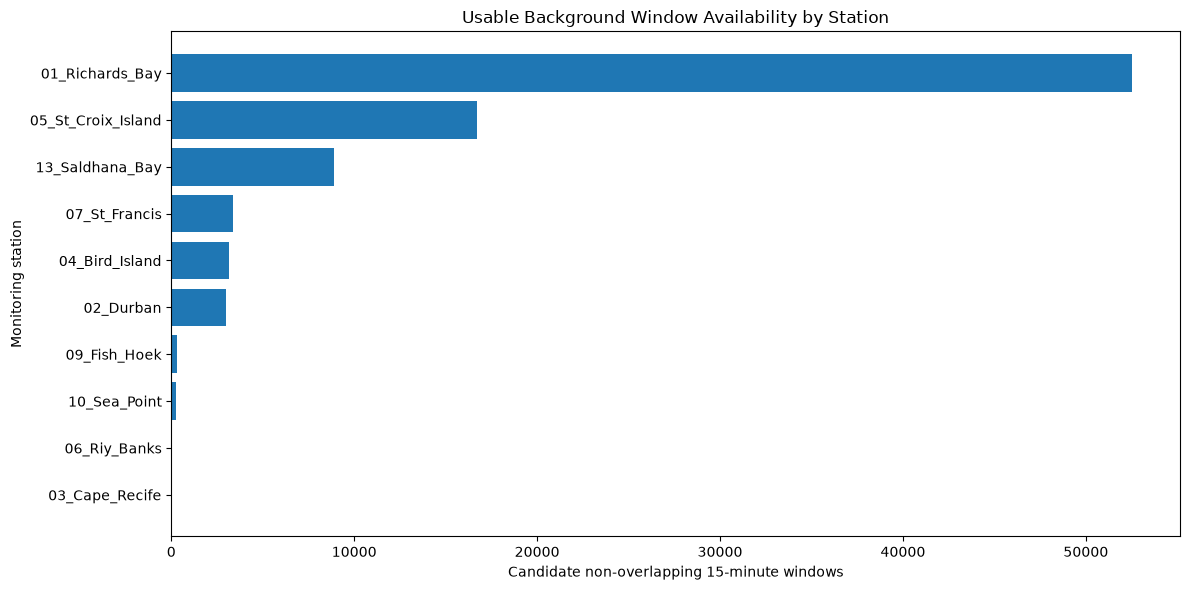

In [71]:
plot_df = continuity_df.sort_values(
    "nonoverlapping_15min_windows",
    ascending=True
)

fig, ax = plt.subplots(figsize=(12, 6))

ax.barh(
    plot_df["station"],
    plot_df["nonoverlapping_15min_windows"]
)

ax.set_xlabel("Candidate non-overlapping 15-minute windows")
ax.set_ylabel("Monitoring station")
ax.set_title("Usable Background Window Availability by Station")

plt.tight_layout()
plt.show()

In [72]:
output_path = REPORT_DIR / "temporal_continuity_summary.csv"

continuity_df.to_csv(output_path, index=False)

print("Saved:", output_path)

Saved: /Users/qwaku/Codes/QBE/Zindi/french-embassy-underwater-vessel-noise-challenge/reports/eda/temporal_continuity_summary.csv


## 6. Recording Interval Diagnostics

In [73]:
# Diagnose timestamp spacing and recording durations.
# Read metadata only; do not load acoustic measurements.

diagnostic_rows = []

for file in parquet_files:
    df = pd.read_parquet(
        file,
        columns=["recorder", "t", "dur"]
    )

    df["t"] = pd.to_datetime(df["t"], errors="coerce")

    for recorder, group in df.groupby("recorder", dropna=False):
        group = group.sort_values("t")

        delta = (
            group["t"]
            .diff()
            .dt.total_seconds()
            .dropna()
        )

        duration = pd.to_numeric(
            group["dur"], errors="coerce"
        )

        # Inspect the most common rounded timestamp intervals.
        common_intervals = (
            delta.round()
            .value_counts()
            .head(5)
        )

        diagnostic_rows.append({
            "station": file.stem,
            "recorder": str(recorder),
            "records": len(group),
            "median_interval_sec": delta.median(),
            "pct_intervals_58_62": (
                100 * delta.between(58, 62).mean()
                if len(delta) else np.nan
            ),
            "pct_intervals_55_65": (
                100 * delta.between(55, 65).mean()
                if len(delta) else np.nan
            ),
            "median_duration_sec": duration.median(),
            "duration_min_sec": duration.min(),
            "duration_max_sec": duration.max(),
            "common_intervals_sec": ", ".join(
                f"{interval:g}s:{count}"
                for interval, count in common_intervals.items()
            )
        })

interval_df = pd.DataFrame(diagnostic_rows)

display(
    interval_df.sort_values(
        ["station", "recorder"]
    )
)

interval_df.to_csv(
    REPORT_DIR / "recorder_interval_diagnostics.csv",
    index=False
)

print("Recorder configurations:", len(interval_df))

,station,recorder,records,median_interval_sec,pct_intervals_58_62,pct_intervals_55_65,median_duration_sec,duration_min_sec,duration_max_sec,common_intervals_sec
0,01_Richards_Bay,201383949_Richards_Bay_201383949.1.24000,492310,60.0,99.746704,99.753204,60.0,1.0,360.0,"60s:480468, 58s:5331, 62s:5251, 29s:392, 91s:391"
1,01_Richards_Bay,5708_Richards_Bay_5708.1.24000,160798,60.0,97.754311,97.962027,60.0,1.0,71.0,"60s:156363, 120s:754, 58s:400, 62s:393, 45s:117"
2,01_Richards_Bay,7005_Richards_Bay_7005.1.24000,348066,60.0,96.753767,96.972405,60.0,2.0,60.0,"60s:336467, 2s:4825, 118s:4822, 89s:426, 31s:426"
3,02_Durban,8230_ST600_8230.1.48000,44640,60.0,99.997760,99.997760,60.0,59.0,60.0,"60s:44632, 61s:3, 59s:3, 777660s:1"
4,03_Cape_Recife,8210_ST600_8210.1.48000,5928,60.0,92.323266,92.323266,60.0,60.0,60.0,"60s:5472, 2880s:455"
5,04_Bird_Island,URN.BirdIsland.2022_6509.1.24000,46472,60.0,99.857976,99.857976,60.0,2.0,60.0,"60s:46405, 2s:32, 86458s:27, 842460s:3, 1.0368..."
6,04_Bird_Island,URN_8321_8321.1.12000,1080,60.0,100.000000,100.000000,60.0,58.0,60.0,60s:1079
7,05_St_Croix_Island,URN.BirdIsland.2022_6509.1.24000,45163,60.0,99.869359,99.869359,60.0,2.0,60.0,"60s:45097, 2s:26, 86458s:23, 86402s:6, 58s:6"
8,05_St_Croix_Island,URN.StCroix.2022_6509.1.24000,70116,60.0,99.864508,99.864508,60.0,2.0,60.0,"60s:70013, 2s:43, 86458s:38, 58s:7, 86402s:6"
9,05_St_Croix_Island,URN_8321_8321.1.12000,135438,60.0,99.960129,99.964559,60.0,2.0,60.0,"60s:135353, 58s:30, 86402s:26, 86403s:6, 57s:6"


Recorder configurations: 17


In [74]:
suspicious = interval_df[
    interval_df["station"].str.contains(
        "Cape_Recife|Riy_Banks|St_Francis|Fish_Hoek",
        regex=True
    )
]

display(
    suspicious[
        [
            "station",
            "recorder",
            "records",
            "median_interval_sec",
            "pct_intervals_58_62",
            "median_duration_sec",
            "common_intervals_sec"
        ]
    ]
)

,station,recorder,records,median_interval_sec,pct_intervals_58_62,median_duration_sec,common_intervals_sec
4,03_Cape_Recife,8210_ST600_8210.1.48000,5928,60.0,92.323266,60.0,"60s:5472, 2880s:455"
10,06_Riy_Banks,8230_ST600_8230.1.48000,4121,60.0,92.330097,60.0,"60s:3804, 2880s:296, 6480s:17, 780480s:2, 1008..."
11,07_St_Francis,SM2M_Cape_StFrancis_SM2M.1.48000,169488,60.0,83.979302,60.0,"60s:142334, 960s:23759, 2760s:3362, 778560s:10..."
12,09_Fish_Hoek,ST300_201650217_ST201650217.1.96000,49260,60.0,79.179439,60.0,"60s:32149, 58s:6852, 362s:6840, 360s:2383, 49s..."
13,09_Fish_Hoek,ST300_5344_ST5344.1.96000,4507,60.0,99.800266,60.0,"60s:4491, 120s:5, 61s:3, 59s:3, 25s:2"


## 7. Continuous Recording Run-Length Distribution

In [75]:
# Summarize continuous run lengths by station.
# No acoustic measurements or test labels are loaded.

run_summaries = []
run_details = []

for file in parquet_files:
    df = pd.read_parquet(
        file,
        columns=["recorder", "t", "dur"]
    )

    df["t"] = pd.to_datetime(df["t"], errors="coerce")
    df["dur"] = pd.to_numeric(df["dur"], errors="coerce")

    for recorder, group in df.groupby(
        "recorder", dropna=False
    ):
        group = group.sort_values("t").reset_index(drop=True)

        valid = group["t"].notna() & group["dur"].between(
            55, 65
        )

        duplicate = group["t"].duplicated(keep=False)
        valid = valid & ~duplicate

        delta = group["t"].diff().dt.total_seconds()

        # A run continues only across a valid 58–62 s step.
        continues = (
            delta.between(58, 62)
            & valid
            & valid.shift(1, fill_value=False)
        )

        run_id = (~continues).cumsum()

        good = group.loc[valid].copy()
        good["run_id"] = run_id.loc[valid].to_numpy()

        lengths = good.groupby("run_id").size()

        for length, count in lengths.value_counts().items():
            run_details.append({
                "station": file.stem,
                "recorder": str(recorder),
                "run_length_minutes": int(length),
                "number_of_runs": int(count)
            })

        run_summaries.append({
            "station": file.stem,
            "recorder": str(recorder),
            "runs": len(lengths),
            "runs_13_or_more": int((lengths >= 13).sum()),
            "runs_15_or_more": int((lengths >= 15).sum()),
            "candidate_full_windows": int(
                (lengths // 15).sum()
            ),
            "maximum_run": (
                int(lengths.max()) if len(lengths) else 0
            )
        })

run_summary_df = pd.DataFrame(run_summaries)
run_length_df = pd.DataFrame(run_details)

station_run_summary = (
    run_summary_df
    .groupby("station", as_index=False)
    .agg({
        "runs": "sum",
        "runs_13_or_more": "sum",
        "runs_15_or_more": "sum",
        "candidate_full_windows": "sum",
        "maximum_run": "max"
    })
)

display(station_run_summary)

print(
    "Total candidate full windows:",
    station_run_summary["candidate_full_windows"].sum()
)


,station,runs,runs_13_or_more,runs_15_or_more,candidate_full_windows,maximum_run
0,01_Richards_Bay,15045,14324,14318,52522,9664
1,02_Durban,2,2,2,2976,37440
2,03_Cape_Recife,456,456,0,0,13
3,04_Bird_Island,36,36,36,3168,1440
4,05_St_Croix_Island,137,131,131,16697,83040
5,06_Riy_Banks,317,317,0,0,13
6,07_St_Francis,27154,3371,3371,3371,15
7,09_Fish_Hoek,9765,8,8,297,1079
8,10_Sea_Point,2,2,2,244,3300
9,13_Saldhana_Bay,303,301,301,8868,1139


Total candidate full windows: 88143


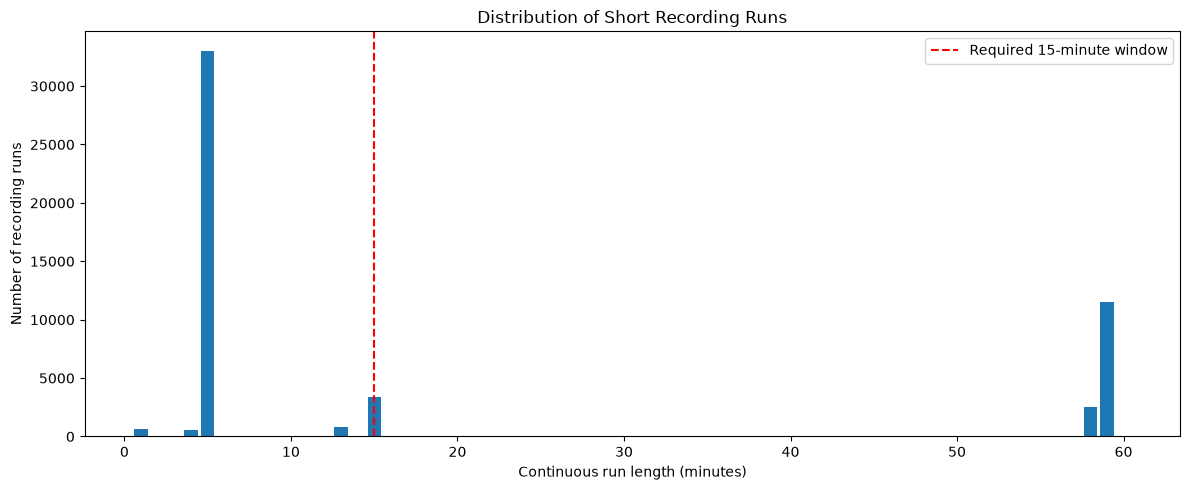

In [76]:
run_distribution = (
    run_length_df.loc[
        run_length_df["run_length_minutes"] <= 60
    ]
    .groupby("run_length_minutes")["number_of_runs"]
    .sum()
)

fig, ax = plt.subplots(figsize=(12, 5))

ax.bar(
    run_distribution.index,
    run_distribution.values
)

ax.axvline(
    15, linestyle="--", color="red",
    label="Required 15-minute window"
)

ax.set_xlabel("Continuous run length (minutes)")
ax.set_ylabel("Number of recording runs")
ax.set_title("Distribution of Short Recording Runs")
ax.legend()

plt.tight_layout()
plt.show()

In [77]:
station_run_summary.to_csv(
    REPORT_DIR / "station_run_length_summary.csv",
    index=False
)

run_length_df.to_csv(
    REPORT_DIR / "recorder_run_length_distribution.csv",
    index=False
)

print("Run-length analysis saved.")

Run-length analysis saved.


---
# Lesson 2 — What we built after the first acoustic survey

**Updated 22 November 2026.** The original station analysis above is retained. The sections below explain our later decisions in plain English, and include small checks against the output files on this computer.

**What has been completed:**

- Indexed **88,143** complete, non-overlapping 15-minute background windows from eight stations, after examining 10 stations overall.
- Built and checked a chronological background split with a gap between training and validation. Two stations remain held out.
- Verified the **525 VTUAD WAV files** against their publisher SHA-256 checksum list.
- Reconciled their metadata and grouped recordings by vessel identity.
- Extracted **1,892 one-minute, 25-band digital-power observations** from **487 candidate vessel recordings**.
- Built a second, class-aware vessel split so more vessel classes appear in validation.
- Created our **first 200 training / 80 validation synthetic mixtures** from real background windows and scaled vessel-shaped energy templates.

**What has not happened:** We have **not yet trained a predictor or measured a model's RMSE**. Passing the mixture generator's mathematical checks does not tell us how well it will perform on Zindi's hidden test set.

The code remains in `scripts/`; these notebook sections mainly explain, check and visualize the files those scripts created.

In [78]:
# Shared paths and helper functions for the new lessons.
# All new checks use local reports; no competition test feature values are read.
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

EDA = PROJECT_ROOT / "reports" / "eda"
SYNTH = EDA / "synthetic_v1"

def report_path(name):
    path = EDA / name
    if not path.exists():
        print(f"Not available yet: {path} (run the corresponding script first)")
        return None
    return path

print("Project root:", PROJECT_ROOT)
print("Available results:")
for name in [
    "background_window_index.csv",
    "background_split_manifest_v2.csv",
    "vtuad_metadata_reconciliation.csv",
    "vtuad_source_split_v1.csv",
    "vtuad_source_split_v2.csv",
    "vtuad_minute_band_power_split_v2.csv",
]:
    print(" ", name, (EDA / name).exists())
print("Synthetic files present:", (SYNTH / "train.npz").exists(),
      (SYNTH / "validation.npz").exists())

Project root: /Users/qwaku/Codes/QBE/Zindi/french-embassy-underwater-vessel-noise-challenge
Available results:
  background_window_index.csv True
  background_split_manifest_v2.csv True
  vtuad_metadata_reconciliation.csv True
  vtuad_source_split_v1.csv True
  vtuad_source_split_v2.csv True
  vtuad_minute_band_power_split_v2.csv True
Synthetic files present: True True


## 8. The 15-minute background-window index

We started from **1,715,779 one-minute observations** in the South African archive. A competition example is 15 minutes long and contains 25 acoustic frequency bands. To avoid inventing missing minutes, we indexed only continuous blocks that could be retrieved as a full 15 × 25 window.

Our first index contains **88,143 candidate windows** from eight stations. Cape Recife and Riy Banks did not have enough consecutive minutes in the recording runs we observed, so we left them out instead of filling the gaps with made-up values.

We manually tested retrieval for two windows from each included station (16 checks); all returned 15 minutes and 25 finite band values. This is a useful sample check, **not** a manual inspection of every window.

**Why this matters:** Missing observations or overlapping windows could make training examples misleading. The index points to the original Parquet rows, so we do not need duplicate sound files.

In [79]:
p = report_path("background_window_index.csv")
if p is not None:
    index = pd.read_csv(p, usecols=["station", "run_id", "start_time"])
    print("Indexed windows:", len(index))
    print("Stations:", index.station.nunique())
    print("Continuous recording runs:", index.run_id.nunique())
    display(index.groupby("station").size().sort_values(ascending=False)
            .rename("windows").to_frame())
    assert len(index) == 88143

Indexed windows: 88143
Stations: 8
Continuous recording runs: 18169


,windows
station,
01_Richards_Bay,52522
05_St_Croix_Island,16697
13_Saldhana_Bay,8868
07_St_Francis,3371
04_Bird_Island,3168
02_Durban,2976
09_Fish_Hoek,297
10_Sea_Point,244


## 9. Why we split background recordings by time and whole recording run

Randomly mixing nearby background minutes into training and validation could make validation look easier than it really is. We instead separated the earlier and later recordings in each development station and preserved a time gap.

The **version 2** split fixed four cases where a continuous recording run crossed an active/excluded boundary. Durban's earlier run became training data and its later run became validation data. The final result is **67,463 training windows, 16,946 validation windows, 3,193 excluded windows, and 541 windows from Fish Hoek and Sea Point held aside**.

All six development stations have train/validation gaps of at least nine days. We never deliberately assign a continuous recording run to two groups. The two held-out stations are for a later stress test.

**Remaining limit:** Different recording runs can still share environmental conditions or deployment histories. The split reduces some leakage risks but does not establish perfect independence.

The original manifest remains available. We did not overwrite it.

,windows
split,
train,67463
validation,16946
excluded,3193
station_holdout,541


split,excluded,station_holdout,train,validation
station,,,,
01_Richards_Bay,777,0,41691,10054
02_Durban,0,0,480,2496
04_Bird_Island,384,0,2472,312
05_St_Croix_Island,408,0,13935,2354
07_St_Francis,216,0,2630,525
09_Fish_Hoek,0,297,0,0
10_Sea_Point,0,244,0,0
13_Saldhana_Bay,1408,0,6255,1205


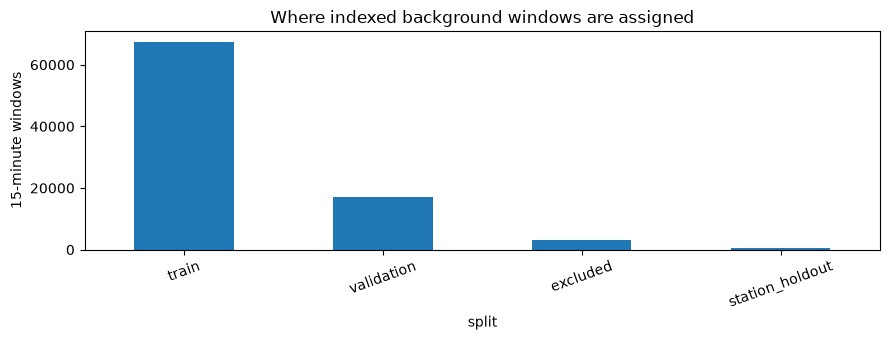

In [80]:
p = report_path("background_split_manifest_v2.csv")
if p is not None:
    bg_split = pd.read_csv(p, usecols=["station", "run_id", "split", "start_time", "last_start_time"])
    counts = bg_split["split"].value_counts()
    display(counts.rename("windows").to_frame())
    display(pd.crosstab(bg_split.station, bg_split.split))
    assert len(bg_split) == 88143
    assert counts.to_dict() == {"train": 67463, "validation": 16946,
                                "excluded": 3193, "station_holdout": 541}
    assert bg_split.groupby("run_id")["split"].nunique().max() == 1
    fig, ax = plt.subplots(figsize=(9, 3.5))
    counts.reindex(["train", "validation", "excluded", "station_holdout"]).plot.bar(ax=ax)
    ax.set_title("Where indexed background windows are assigned")
    ax.set_ylabel("15-minute windows")
    ax.tick_params(axis="x", rotation=20)
    plt.tight_layout()
    plt.show()

## 10. VTUAD: what we verified and what we discovered

VTUAD contains **525 audio files**. All 525 matched their publisher's SHA-256 file checksums and were mono, 32 kHz, 16-bit PCM. A valid checksum tells us the file was copied correctly; it does not prove that the recording contains pure vessel sound or that it was calibrated to underwater pressure units.

We found a naming surprise: **38 recordings are labelled `background`, but only 16 are stored inside the `background/` directory**. The other 22 are inside `vessel/`. We therefore chose sources by **metadata label**, not by folder name: **487** recordings with vessel-class labels became candidate vessel sources, and **38** background-labelled recordings were set aside.

We also found a mismatch between metadata duration and WAV duration in some cases: **353 matched within 0.01 seconds; 168 differed by more than one second; 167 differed by more than 60 seconds**. Audio processing therefore uses the actual WAV samples rather than the metadata duration.

VTUAD's own split was designed at the clip level. We found **57 vessel hull IDs** appearing in more than one of its train/validation/test groups. Because we want an unseen-vessel evaluation, we created our own hull-isolated splits.

**Scientific limit:** VTUAD labels come from AIS tracking conditions. A clip identified with a vessel can still contain ordinary sea noise and other unobserved sounds.

In [81]:
p = report_path("vtuad_metadata_reconciliation.csv")
if p is not None:
    reconcile = pd.read_csv(p)
    print("Metadata records:", len(reconcile))
    print("WAV files found:", int(reconcile.exists.sum()))
    print("Labels versus directory:")
    display(pd.crosstab(reconcile.directory_category, reconcile.label))
    durations = (reconcile.wav_duration - reconcile.metadata_duration).abs()
    print("Duration matches (<0.01 s):", int((durations < 0.01).sum()))
    print("Duration difference >60 s:", int((durations > 60).sum()))
    assert len(reconcile) == 525 and reconcile.exists.all()

Metadata records: 525
WAV files found: 525
Labels versus directory:


label,background,cargo,dredger,fishing,other,passengership,pilotvessel,pleasurecraft,rescue,sailing,tanker,tug
directory_category,,,,,,,,,,,,
background,16,0,0,0,0,0,0,0,0,0,0,0
vessel,22,97,8,34,40,71,2,32,4,6,5,188


Duration matches (<0.01 s): 353
Duration difference >60 s: 167


## 11. Two vessel splits, and why we improved the first one

V1 placed **407 vessel-class recordings** in training and **80** in validation, keeping all recordings of the same known hull together. It passed the identity-leakage check, but several vessel classes appeared in only one group.

We built a **class-aware v2** split: **410 training clips (137 hulls)**, **77 validation clips (35 hulls)**, plus **38 background references**. No hull ID appears in both training and validation. **Nine of eleven vessel classes** are represented on both sides. The exceptions are **dredger** and **pilot vessel**: each class has only one known hull, so splitting its clips between train and validation would violate the independence rule.

We keep v1 for comparison and use v2 as our main development split. Even v2 remains limited: it has very little validation data for rare classes, and separate hulls may have been recorded under similar conditions.

In [82]:
p = report_path("vtuad_source_split_v2.csv")
if p is not None:
    vessel_split = pd.read_csv(p, dtype={"hull_id": "string"})
    display(pd.crosstab(vessel_split.label, vessel_split.source_split))
    active = vessel_split[vessel_split.source_split.isin(["train", "validation"])]
    print("Clips by split:", active.source_split.value_counts().to_dict())
    print("Unique hulls:", active.groupby("source_split").hull_id.nunique().to_dict())
    assert len(vessel_split) == 525 and len(active) == 487
    assert active.groupby("hull_id").source_split.nunique().max() == 1
    assert set(active.loc[active.source_split.eq("train"), "hull_id"]).isdisjoint(
        set(active.loc[active.source_split.eq("validation"), "hull_id"]))
    print("Hull overlap: 0 — PASS")

source_split,background_reference,train,validation
label,,,
background,38,0,0
cargo,0,88,9
dredger,0,8,0
fishing,0,29,5
other,0,37,3
passengership,0,65,6
pilotvessel,0,2,0
pleasurecraft,0,27,5
rescue,0,3,1


Clips by split: {'train': 410, 'validation': 77}
Unique hulls: {'train': 137, 'validation': 35}
Hull overlap: 0 — PASS


## 12. We extracted acoustic features from the vessel recordings

Our Python extractor reads WAV audio **one full minute at a time** and estimates relative digital signal power in the competition's **25 third-octave frequency bands**. The output has **1,892 one-minute records**: **1,530 assigned to training and 362 to validation under v2**.

We first tested the calculation with a known **1,000 Hz sine wave**. It correctly placed most power in the 1 kHz band and recovered mean-square power **0.005** for a signal with amplitude 0.1. A broadband noise test also passed: expected fraction of power within the covered frequency range was **0.5555**, and observed fraction was **0.5568**. Then three real clips passed a smoke test before all 487 eligible recordings were processed.

The full feature audit found **no missing or negative band powers, no zero-power minutes, and no duplicate clip/minute keys**. V2 changed only the training/validation labels, not the acoustic values.

**Important:** These are **digital relative powers**, not calibrated underwater sound-pressure measurements. We cannot add them directly to the South African decibel values.

Minute rows: 1892
Source clips: 487
Band count: 25


source_split,train,validation
label,,
cargo,252,33
dredger,18,0
fishing,133,34
other,129,8
passengership,157,16
pilotvessel,4,0
pleasurecraft,95,22
rescue,25,3
sailing,20,4


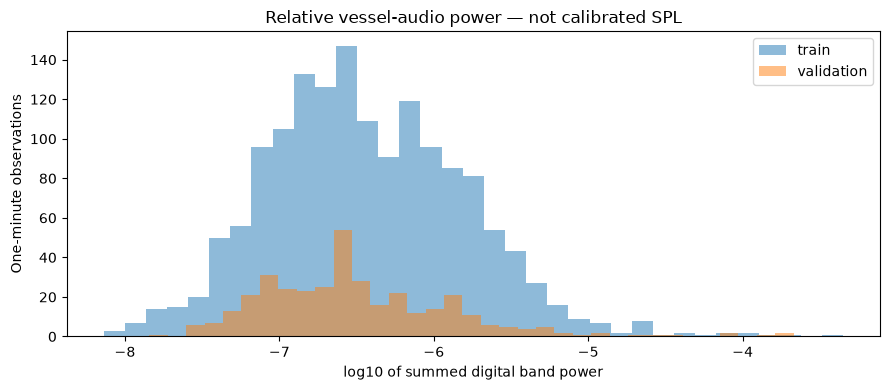

Vessel feature checks: PASS


In [83]:
p = report_path("vtuad_minute_band_power_split_v2.csv")
if p is not None:
    vessel_features = pd.read_csv(p, dtype={"hull_id": "string"})
    vessel_bands = [c for c in vessel_features if c.startswith("TOL_")]
    print("Minute rows:", len(vessel_features))
    print("Source clips:", vessel_features.clip_uid.nunique())
    print("Band count:", len(vessel_bands))
    display(pd.crosstab(vessel_features.label, vessel_features.source_split))
    assert len(vessel_features) == 1892
    assert vessel_features.clip_uid.nunique() == 487
    assert len(vessel_bands) == 25
    power = vessel_features[vessel_bands].to_numpy(dtype=float)
    assert np.isfinite(power).all() and (power >= 0).all()
    assert np.allclose(power.sum(axis=1), vessel_features.relative_total_power,
                       rtol=1e-9, atol=1e-15)
    assert not vessel_features.duplicated(["clip_uid", "minute_index"]).any()
    fig, ax = plt.subplots(figsize=(9, 4))
    for split, group in vessel_features.groupby("source_split"):
        ax.hist(np.log10(group.relative_total_power), bins=35, alpha=0.5,
                label=split)
    ax.set_xlabel("log10 of summed digital band power")
    ax.set_ylabel("One-minute observations")
    ax.set_title("Relative vessel-audio power — not calibrated SPL")
    ax.legend()
    plt.tight_layout()
    plt.show()
    print("Vessel feature checks: PASS")

## 13. Our first controlled vessel-addition simulation

We now have a script named `scripts/build_synthetic_mixtures_v1.py`. It combines real South African background-window profiles with short, scaled vessel-shaped **relative-energy templates**. The program passed its self-test and created a small **24-train / 12-validation** trial. We then generated **200 training mixtures and 80 validation mixtures**, each with an input shape of **15 minutes × 25 bands** and a known simulated target fraction.

The arithmetic works like this: if `B` is background energy, `V` is a nonnegative added template and `a` is its scale, then the simulated mixture is `B + aV`. The known share is the sum of `aV` divided by the sum of `B + aV` across the 15 × 25 cells. We tested this calculation for desired shares of **0%, 5%, 20%, 50% and 80%**; each was recovered to numerical precision.

**Why we did this:** We need examples whose targets we know before we can test whether a model can learn to estimate the added fraction.

**What this does not prove:** We do not know whether Zindi's unseen synthetic mixtures use the same vessel event lengths, acoustic shapes or scaling. VTUAD contains background sound, and our relative scaling does not establish absolute physical calibration. A good RMSE on our own simulated validation set would be evidence only for this simulation setup, not evidence of a good competition score.

The most recent generated datasets are stored at `reports/eda/synthetic_v1/{train,validation}.npz`, with accompanying provenance CSV files. The larger run replaced the small trial's files.

**Representation note:** In the saved `.npz` files, `X` is a logarithmic relative sound level (`10 × log10` of simulated relative energy), not raw linear energy. Its values can be negative. When auditing `X`, we check that its values are finite and that conversion back to linear energy is positive. The target `y` is a fraction between 0 and 1.


In [84]:
# Inspect generated arrays without rebuilding them.
# IMPORTANT: X contains logarithmic relative acoustic levels (10*log10(energy)),
# not nonnegative linear energy. Negative X values are valid.
for split, expected_n in [("train", 200), ("validation", 80)]:
    p = SYNTH / f"{split}.npz"
    if not p.exists():
        print(f"Not available yet: {p}")
        continue

    with np.load(p, allow_pickle=False) as archive:
        print(f"{split}: available keys = {archive.files}")
        assert {"X", "y"}.issubset(archive.files)
        X, y = archive["X"], archive["y"]
        print("  X shape:", X.shape, "y shape:", y.shape)
        print("  Log-level range:", float(X.min()), "to", float(X.max()))
        print("  Target range:", float(y.min()), "to", float(y.max()))
        print("  Target average:", float(y.mean()))

        assert X.shape == (expected_n, 15, 25)
        assert y.shape == (expected_n,)
        assert np.issubdtype(X.dtype, np.floating)
        assert np.isfinite(X).all() and np.isfinite(y).all()
        # Logarithmic values may legitimately be negative. Converting back to
        # relative linear energy must produce finite, strictly positive values.
        linear_energy = np.power(10.0, X.astype(np.float64) / 10.0)
        assert np.isfinite(linear_energy).all()
        assert (linear_energy > 0).all()
        assert ((y >= 0) & (y < 1)).all()
        print("  Negative log-level cells (valid):", int((X < 0).sum()))
        print("  Zero-addition targets:", int((y == 0).sum()))

    csv_path = SYNTH / f"{split}_provenance.csv"
    if csv_path.exists():
        trace = pd.read_csv(csv_path)
        print("  Provenance records:", len(trace))
        print("  Provenance columns:", trace.columns.tolist())
        display(trace.head(3))
        assert len(trace) == expected_n
        if {"requested_share", "recovered_share"}.issubset(trace.columns):
            requested = trace["requested_share"].to_numpy(dtype=float)
            recovered = trace["recovered_share"].to_numpy(dtype=float)
            assert np.allclose(requested, recovered, atol=1e-10)
            assert np.allclose(y, recovered, atol=1e-6)
    print()

print("Synthetic file audit: PASS (log-level representation validated).")
print("These are simulated targets, not competition labels.")

train: available keys = ['X', 'y']
  X shape: (200, 15, 25) y shape: (200,)
  Log-level range: -113.0 to 11.775837898254395
  Target range: 0.0 to 0.699999988079071
  Target average: 0.28075000643730164
  Negative log-level cells (valid): 74093
  Zero-addition targets: 34
  Provenance records: 200
  Provenance columns: ['example', 'partition', 'station', 'background_run_id', 'background_start', 'background_source', 'vessel_clip_uid', 'vessel_hull_id', 'vessel_class', 'vessel_duration_min', 'vessel_audio_start_min', 'inserted_start_min', 'requested_share', 'recovered_share', 'relative_scale']


,example,partition,station,background_run_id,background_start,background_source,vessel_clip_uid,vessel_hull_id,vessel_class,vessel_duration_min,vessel_audio_start_min,inserted_start_min,requested_share,recovered_share,relative_scale
0,0,train,01_Richards_Bay,01_Richards_Bay|201383949_Richards_Bay_2013839...,2019-09-05 15:30:00,data/zindi/extracted/acoustics/01_Richards_Bay...,NaN,NaN,NaN,0,-1,-1,0.00,0.00,0.000000e+00
1,1,train,01_Richards_Bay,01_Richards_Bay|5708_Richards_Bay_5708.1.24000...,2021-07-31 17:15:00,data/zindi/extracted/acoustics/01_Richards_Bay...,4ff2004f178bdd65,H071,rescue,14,0,1,0.05,0.05,1.272376e+05
2,2,train,01_Richards_Bay,01_Richards_Bay|5708_Richards_Bay_5708.1.24000...,2021-05-05 16:08:00,data/zindi/extracted/acoustics/01_Richards_Bay...,c9895bb272520c0e,H027,passengership,2,0,4,0.15,0.15,1.432925e+06



validation: available keys = ['X', 'y']
  X shape: (80, 15, 25) y shape: (80,)
  Log-level range: -63.099998474121094 to 11.737883567810059
  Target range: 0.0 to 0.699999988079071
  Target average: 0.27687495946884155
  Negative log-level cells (valid): 29641
  Zero-addition targets: 14
  Provenance records: 80
  Provenance columns: ['example', 'partition', 'station', 'background_run_id', 'background_start', 'background_source', 'vessel_clip_uid', 'vessel_hull_id', 'vessel_class', 'vessel_duration_min', 'vessel_audio_start_min', 'inserted_start_min', 'requested_share', 'recovered_share', 'relative_scale']


,example,partition,station,background_run_id,background_start,background_source,vessel_clip_uid,vessel_hull_id,vessel_class,vessel_duration_min,vessel_audio_start_min,inserted_start_min,requested_share,recovered_share,relative_scale
0,0,validation,01_Richards_Bay,01_Richards_Bay|7005_Richards_Bay_7005.1.24000...,2024-02-07 14:30:00,data/zindi/extracted/acoustics/01_Richards_Bay...,NaN,NaN,NaN,0,-1,-1,0.00,0.00,0.000000e+00
1,1,validation,01_Richards_Bay,01_Richards_Bay|7005_Richards_Bay_7005.1.24000...,2024-02-07 06:30:00,data/zindi/extracted/acoustics/01_Richards_Bay...,159579b2f17cefa6,H122,passengership,2,0,9,0.05,0.05,1.786910e+06
2,2,validation,02_Durban,02_Durban|8230_ST600_8230.1.48000|2,2025-12-04 16:30:00,data/zindi/extracted/acoustics/02_Durban.parquet,830e7eb1ef1c5601,H176,other,3,0,12,0.15,0.15,1.618181e+06



Synthetic file audit: PASS (log-level representation validated).
These are simulated targets, not competition labels.


## 14. Progress after the first simulation

The original work above is preserved. After completing the first **200 train / 80 validation** synthetic mixtures, we trained three baseline models and carried out further diagnostics. The following lessons show **what we observed**, **why we tested it**, and **what remains uncertain**.

The values below describe our own simulation only. None of them is a Zindi hidden-test score. Our next independent experiment will be called **Synthetic Experiment 002**. The existing Experiment 001 files must not be overwritten when creating it.

## 15. Inspect the provenance before changing our simulation

The generator accepts `--train`, `--validation`, `--seed` and `--self-test`. It records which background window and vessel recording were used, where a short event was placed, and the simulated share and scaling factor.

**Why this matters:** We can redesign the experiment without losing track of its sources. A zero-addition example correctly has no vessel clip or hull, and its added-energy fraction is zero.

In [85]:
# Read provenance already written by the generator; do not regenerate mixtures.
provenance = {}
for split, expected in [("train", 200), ("validation", 80)]:
    path = SYNTH / f"{split}_provenance.csv"
    if not path.exists():
        print(f"Missing provenance: {path}")
        continue
    df = pd.read_csv(path)
    assert len(df) == expected
    essential = {"station", "background_run_id", "vessel_clip_uid", "vessel_hull_id",
                 "vessel_duration_min", "inserted_start_min", "requested_share", "recovered_share"}
    assert essential.issubset(df.columns)
    assert np.allclose(df["requested_share"], df["recovered_share"], atol=1e-8)
    provenance[split] = df
    print(f"\n{split}: {len(df)} examples; {df['station'].nunique()} stations")
    print("Zero-addition examples:", int(df['requested_share'].eq(0).sum()))
    print("Stations:")
    display(df['station'].value_counts().to_frame('examples'))
    print("Vessel event duration (positive additions):")
    display(df.loc[df['requested_share'].gt(0), 'vessel_duration_min'].describe().to_frame('minutes'))
    display(df.head(3))
if len(provenance) == 2:
    tr, va = provenance['train'], provenance['validation']
    for key in ['background_run_id', 'vessel_clip_uid', 'vessel_hull_id']:
        a = set(tr[key].dropna().astype(str))
        b = set(va[key].dropna().astype(str))
        assert a.isdisjoint(b), f"Cross-partition overlap in {key}"
    print("Provenance source-overlap audit: PASS")


train: 200 examples; 5 stations
Zero-addition examples: 34
Stations:


,examples
station,
01_Richards_Bay,119
05_St_Croix_Island,53
13_Saldhana_Bay,14
04_Bird_Island,9
07_St_Francis,5


Vessel event duration (positive additions):


,minutes
count,166.000000
mean,3.855422
std,2.577913
min,1.000000
25%,2.000000
50%,3.000000
75%,4.000000
max,15.000000


,example,partition,station,background_run_id,background_start,background_source,vessel_clip_uid,vessel_hull_id,vessel_class,vessel_duration_min,vessel_audio_start_min,inserted_start_min,requested_share,recovered_share,relative_scale
0,0,train,01_Richards_Bay,01_Richards_Bay|201383949_Richards_Bay_2013839...,2019-09-05 15:30:00,data/zindi/extracted/acoustics/01_Richards_Bay...,NaN,NaN,NaN,0,-1,-1,0.00,0.00,0.000000e+00
1,1,train,01_Richards_Bay,01_Richards_Bay|5708_Richards_Bay_5708.1.24000...,2021-07-31 17:15:00,data/zindi/extracted/acoustics/01_Richards_Bay...,4ff2004f178bdd65,H071,rescue,14,0,1,0.05,0.05,1.272376e+05
2,2,train,01_Richards_Bay,01_Richards_Bay|5708_Richards_Bay_5708.1.24000...,2021-05-05 16:08:00,data/zindi/extracted/acoustics/01_Richards_Bay...,c9895bb272520c0e,H027,passengership,2,0,4,0.15,0.15,1.432925e+06



validation: 80 examples; 5 stations
Zero-addition examples: 14
Stations:


,examples
station,
01_Richards_Bay,46
02_Durban,13
05_St_Croix_Island,11
13_Saldhana_Bay,8
07_St_Francis,2


Vessel event duration (positive additions):


,minutes
count,66.000000
mean,4.257576
std,2.585823
min,2.000000
25%,3.000000
50%,4.000000
75%,4.000000
max,15.000000


,example,partition,station,background_run_id,background_start,background_source,vessel_clip_uid,vessel_hull_id,vessel_class,vessel_duration_min,vessel_audio_start_min,inserted_start_min,requested_share,recovered_share,relative_scale
0,0,validation,01_Richards_Bay,01_Richards_Bay|7005_Richards_Bay_7005.1.24000...,2024-02-07 14:30:00,data/zindi/extracted/acoustics/01_Richards_Bay...,NaN,NaN,NaN,0,-1,-1,0.00,0.00,0.000000e+00
1,1,validation,01_Richards_Bay,01_Richards_Bay|7005_Richards_Bay_7005.1.24000...,2024-02-07 06:30:00,data/zindi/extracted/acoustics/01_Richards_Bay...,159579b2f17cefa6,H122,passengership,2,0,9,0.05,0.05,1.786910e+06
2,2,validation,02_Durban,02_Durban|8230_ST600_8230.1.48000|2,2025-12-04 16:30:00,data/zindi/extracted/acoustics/02_Durban.parquet,830e7eb1ef1c5601,H176,other,3,0,12,0.15,0.15,1.618181e+06


Provenance source-overlap audit: PASS


## 16. Our first prediction models

We trained models using **200 synthetic examples** and evaluated them on **80 separate synthetic examples**. They were not given vessel identities or the known added-energy fractions as input features.

| Model | RMSE | MAE |
|---|---:|---:|
| Constant training average | 0.249648 | 0.217644 |
| Ridge regression | 0.266875 | 0.218580 |
| Random Forest (200 trees) | **0.197845** | **0.159288** |

**What this means:** A Random Forest learned more than simply predicting the average, but it was not accurate across the whole range. The model typically predicted some added vessel energy even when the correct share was zero, and it underpredicted large vessel contributions. This is a *synthetic validation result*, not a competition score.

The reports are under `reports/baselines/synthetic_v1/`. The code cell below reads them if they exist.

,model,rmse,mae,bias,prediction_min,prediction_max
0,random_forest_200,0.197845,0.159288,-0.010119,0.044617,0.583206
1,constant_train_mean,0.249648,0.217644,0.003875,0.280750,0.280750
2,ridge_alpha_10,0.266875,0.218580,0.002549,0.000000,0.696511


,example,station,vessel_class,vessel_duration_min,requested_share,actual_share,constant_train_mean,ridge_alpha_10,random_forest_200
0,0,01_Richards_Bay,NaN,0,0.00,0.00,0.28075,0.352918,0.193359
1,1,01_Richards_Bay,passengership,2,0.05,0.05,0.28075,0.333488,0.168727
2,2,02_Durban,other,3,0.15,0.15,0.28075,0.167248,0.183099
3,3,01_Richards_Bay,tug,4,0.30,0.30,0.28075,0.303233,0.062399
4,4,05_St_Croix_Island,cargo,3,0.50,0.50,0.28075,0.093105,0.160131
5,5,01_Richards_Bay,tug,3,0.70,0.70,0.28075,0.136686,0.409039
6,6,13_Saldhana_Bay,NaN,0,0.00,0.00,0.28075,0.067347,0.064892
7,7,01_Richards_Bay,tug,3,0.05,0.05,0.28075,0.291780,0.219394


,requested_share,n,actual,predicted
0,0.00,14,0.00,0.190442
1,0.05,14,0.05,0.161808
2,0.15,13,0.15,0.223227
3,0.30,13,0.30,0.284092
4,0.50,13,0.50,0.320161
5,0.70,13,0.70,0.434746


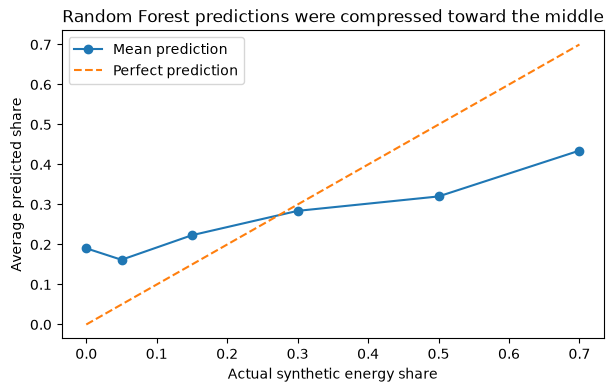

In [86]:
# Model reports from Experiment 001 — no model retraining here.
BASELINE = PROJECT_ROOT / "reports" / "baselines" / "synthetic_v1"
metrics_path = BASELINE / "metrics.csv"
predictions_path = BASELINE / "validation_predictions.csv"
if metrics_path.exists() and predictions_path.exists():
    baseline_metrics = pd.read_csv(metrics_path)
    baseline_predictions = pd.read_csv(predictions_path)
    display(baseline_metrics.sort_values("rmse"))
    assert len(baseline_predictions) == 80
    needed = {"actual_share", "random_forest_200", "constant_train_mean", "station", "requested_share"}
    assert needed.issubset(baseline_predictions.columns)
    display(baseline_predictions.head(8))
    by_share = (baseline_predictions.groupby('requested_share')
                .agg(n=('actual_share','size'),
                     actual=('actual_share','mean'),
                     predicted=('random_forest_200','mean'))
                .reset_index())
    display(by_share)
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(by_share['actual'], by_share['predicted'], marker='o', label='Mean prediction')
    ax.plot([0, 0.7], [0, 0.7], linestyle='--', label='Perfect prediction')
    ax.set(xlabel='Actual synthetic energy share', ylabel='Average predicted share',
           title='Random Forest predictions were compressed toward the middle')
    ax.legend()
    plt.show()
else:
    print('Missing Experiment 001 baseline reports; run scripts/train_synthetic_baselines_v1.py locally.')

## 17. Statistical checks on the first Random Forest

We tested whether Random Forest's advantage over predicting a constant was stable **within the same 80 simulated validation examples**.

- Random Forest RMSE: **0.197845**; constant RMSE: **0.249648**; improvement: **0.051803**.
- Paired-bootstrap 95% interval for improvement: **0.020786 to 0.083729**.
- Fraction of bootstrap resamples with improvement: **0.9994**.
- Shuffling target labels within each background station produced a median RMSE of **0.290046**. The permutation p-value was **0.00020**.

**Why we did this:** To test whether the improvement might be a chance association with the particular simulation labels. **Important limitation:** Related recordings and our synthetic data-generation rules can make these checks look stronger than the evidence would be on genuinely independent acoustic events.

In [87]:
# Recalculate the observed improvement and direction of error.
# The bootstrap/permutation figures above are recorded outputs from the prior terminal experiment.
if 'baseline_predictions' in globals():
    df = baseline_predictions
    y = df['actual_share'].to_numpy(float)
    rf = df['random_forest_200'].to_numpy(float)
    constant = df['constant_train_mean'].to_numpy(float)
    rmse = lambda a, b: float(np.sqrt(np.mean((a - b)**2)))
    print('Constant RMSE:', round(rmse(y, constant), 6))
    print('Random Forest RMSE:', round(rmse(y, rf), 6))
    print('RMSE improvement:', round(rmse(y, constant) - rmse(y, rf), 6))
    table = (df.assign(signed_error=df['random_forest_200'] - df['actual_share'])
             .groupby('requested_share')
             .agg(n=('actual_share','size'), mean_prediction=('random_forest_200','mean'),
                  mean_signed_error=('signed_error','mean')))
    display(table)
else:
    print('Run the previous baseline-report cell first.')

Constant RMSE: 0.249648
Random Forest RMSE: 0.197845
RMSE improvement: 0.051803


,n,mean_prediction,mean_signed_error
requested_share,,,
0.00,14,0.190442,0.190442
0.05,14,0.161808,0.111808
0.15,13,0.223227,0.073227
0.30,13,0.284092,-0.015908
0.50,13,0.320161,-0.179839
0.70,13,0.434746,-0.265254


## 18. The biggest discovery: acoustic summaries work better

We compared five representations on the **same** 200/80 synthetic data, using 200-tree Random Forests. Results:

| Features | Count | RMSE |
|---|---:|---:|
| All raw minute-by-band values | 375 | 0.196201 |
| Overall sound statistics | 4 | 0.196340 |
| Average and spread for each frequency band | 50 | 0.147325 |
| Changes between minutes | 42 | 0.208288 |
| **Global + spectral + temporal summaries** | **96** | **0.119687** |

**What we learned:** Summarizing how sound is distributed across frequencies, together with how it changes over minutes, helped this model more than using every raw measurement directly. The combined representation was our best exploratory choice.

**What we must not claim:** We tried several options against the same 80 validation examples and then chose the best one. Therefore, **0.119687 may be optimistic**. We should freeze this feature design as a candidate and test it on **fresh examples** in Experiment 002.

In [88]:
# Optional: reproduce the five feature-family comparisons on Experiment 001.
# This is exploratory only: reuse of the same 80 validation rows is NOT independent testing.
from sklearn.ensemble import RandomForestRegressor
if (SYNTH / 'train.npz').exists() and (SYNTH / 'validation.npz').exists():
    with np.load(SYNTH / 'train.npz', allow_pickle=False) as a, \
         np.load(SYNTH / 'validation.npz', allow_pickle=False) as b:
        Xtr, ytr = a['X'].astype(np.float64), a['y']
        Xva, yva = b['X'].astype(np.float64), b['y']
    assert Xtr.shape == (200,15,25) and Xva.shape == (80,15,25)
    def feature_families(X):
        d = np.diff(X, axis=1)
        overall = np.column_stack([X.mean((1,2)), X.std((1,2)),
                                   X.min((1,2)), X.max((1,2))])
        spectral = np.column_stack([X.mean(axis=1), X.std(axis=1)])
        temporal = np.column_stack([d.mean(axis=2), d.std(axis=2),
                                    np.abs(d).mean(axis=2)])
        return {'raw_375': X.reshape(len(X),-1), 'global_4': overall,
                'spectral_50': spectral, 'temporal_42': temporal,
                'combined_96': np.column_stack([overall,spectral,temporal])}
    trf, vaf = feature_families(Xtr), feature_families(Xva)
    results = []
    for name, arr in trf.items():
        model = RandomForestRegressor(n_estimators=200,min_samples_leaf=2,
                                      random_state=42,n_jobs=-1)
        model.fit(arr,ytr)
        pred = np.clip(model.predict(vaf[name]),0,1)
        results.append({'features':name,'count':arr.shape[1],
                        'rmse':float(np.sqrt(np.mean((yva-pred)**2)))})
    display(pd.DataFrame(results).sort_values('rmse'))
else:
    print('Experiment 001 NPZ files not found locally.')

,features,count,rmse
4,combined_96,96,0.119687
2,spectral_50,50,0.147325
0,raw_375,375,0.196201
1,global_4,4,0.196340
3,temporal_42,42,0.208288


## 19. What we will do next: Synthetic Experiment 002

We have enough evidence to design a stronger second experiment. We will preserve Experiment 001 and its original reports, inspect the full distributions recorded in the provenance tables, and deliberately vary the simulated vessel fractions, event lengths and insertion positions.

We will continue separating background runs and vessel hulls between training and validation, and we will evaluate the already-selected **combined 96-feature model** against fresh simulated validation examples. We will compare it with simpler baselines and examine errors by station, event strength and source class.

The 25-band extractor still uses relative digital power and approximate third-octave integration. Acoustic calibration, source contamination and exact replication of the competition's hidden data-generation conditions remain open scientific questions. **We have not generated a competition leaderboard score.**

The research log `PROJECT_LEARNING_LOG.md` has been updated with full explanations in plain English.